### ***3D-CFD Plotter***

在`CASE_NAME`中确认算例名称，随后逐块调用 `3Dplot/` 下的绘图模块。

In [1]:
# 每次修改该名称
CASE_NAME = '3D-7-cyc-urans-tfbf'

In [2]:
%matplotlib inline

import sys
from pathlib import Path

REPO_ROOT = next(q for q in [Path.cwd(), *Path.cwd().parents] if (q / 'pyproject.toml').exists())
sys.path.insert(0, str(REPO_ROOT / 'src' / '3D' / '3Dplot'))

from cfd_style import apply_style
from cfd_case import load_case, load_snapshots
from cfd_residual import plot_residual
from cfd_forces import plot_forces
from cfd_spectrum import plot_spectrum
from cfd_surface import plot_cp_surface, plot_cp_surface_time
from cfd_fields import load_field, plot_sections, plot_w_top, plot_wide_view
from cfd_vortex import plot_q_criterion

apply_style()
case = load_case(CASE_NAME)

print(f'repo  : {REPO_ROOT}')
print(f'case  : {case.case_dir}')
print(f'figs  : {case.fig_dir}')
print(f'cases : {[q.name for q in sorted((REPO_ROOT / "data").glob("3D-*"))]}')

repo  : C:\Users\Administrator\Desktop\PurineCFD-Plugin
case  : C:\Users\Administrator\Desktop\PurineCFD-Plugin\data\3D-7-cyc-urans-tfbf
figs  : C:\Users\Administrator\Desktop\PurineCFD-Plugin\results\3D-7-cyc-urans-tfbf
cases : ['3D-1-cylinder-Re1000', '3D-2-cyc-lusgs', '3D-3-cyc-lusgs', '3D-4-cyc-urans', '3D-5-cyc-urans', '3D-6-cyc-urans-i20', '3D-7-cyc-urans-tfbf', '3D-8-cyc-urans-rf', '3D-9-cyc-urans-rf']


观测残差下降图像，其中 *res0* 表示内迭代残差，*res* 表示总残差。

rows = 1000, inner residual = True
steady rows = 0, transient rows = 1000
res = 1.5060e-08 -> 1.0288e-09
res0 = 4.5857e-06 -> 3.1831e-07
C:\Users\Administrator\Desktop\PurineCFD-Plugin\results\3D-7-cyc-urans-tfbf\residual.png


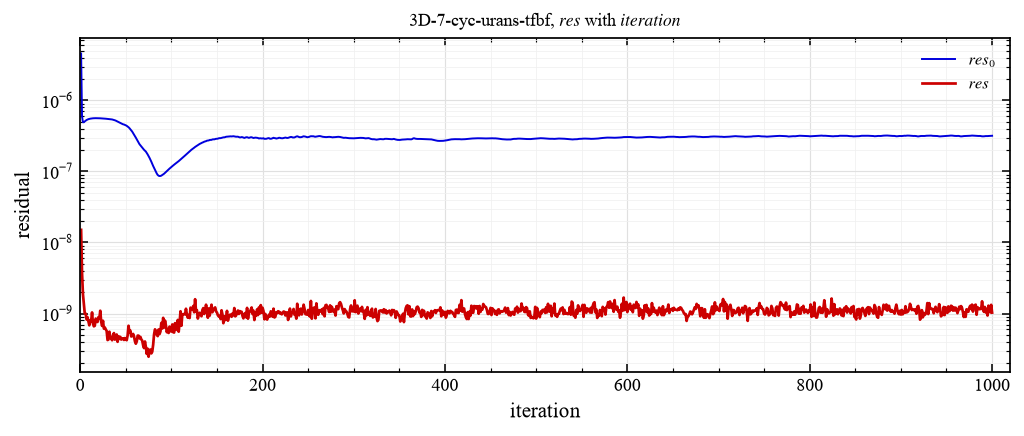

In [3]:
plot_residual(case)

读取 `history.csv` 的升力系数 $C_L$ 与阻力系数 $C_D$

D = 0.9995 m, snapshots used = 10
Mean Cd (history total)  = 1.2633
Mean Cd (pressure only)  = 1.1661
Mean friction contribution = 0.0972
 step   time  cd_full  cl_full  cd_hist  friction_cd
  100 0.1500   0.9149   0.6630   0.9911       0.0762
  200 0.3000   1.1412   0.8221   1.2330       0.0918
  300 0.4500   1.1704   0.8160   1.2665       0.0961
  400 0.6000   1.2210   0.8703   1.3201       0.0991
  500 0.7500   1.2188   0.6882   1.3204       0.1015
  600 0.9000   1.1707   0.3281   1.2721       0.1014
  700 1.0500   1.0981  -0.3096   1.1957       0.0976
  800 1.2000   1.2019  -0.9052   1.3017       0.0998
  900 1.3500   1.2962  -0.9507   1.4006       0.1045
 1000 1.5000   1.2275  -0.5525   1.3312       0.1037
C:\Users\Administrator\Desktop\PurineCFD-Plugin\results\3D-7-cyc-urans-tfbf\force_history.png


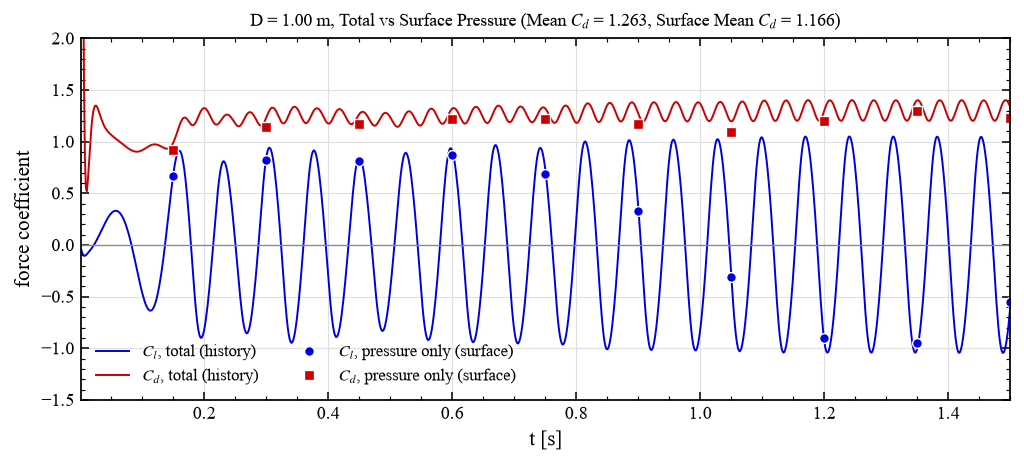

In [4]:
snaps = load_snapshots(case)
plot_forces(case, snaps.force)

对 $C_L$ 做频谱分析，给出 FFT 幅值谱、PSD 与斯特劳哈尔数 $St = fD/U_\infty$。

samples = 1000, dt = 0.00150 s, fs = 666.67 Hz
window = 0.0015 ... 1.5000 s, raw df = 0.667 Hz
dominant frequency (FFT peak) = 13.8794 Hz
D = 0.9995 m, U_inf = 69.6232 m/s
Strouhal number St = 0.1993
uncertainty: df = +/-0.333 Hz, dSt = +/-0.0048
C:\Users\Administrator\Desktop\PurineCFD-Plugin\results\3D-7-cyc-urans-tfbf\cl_fft_psd.png


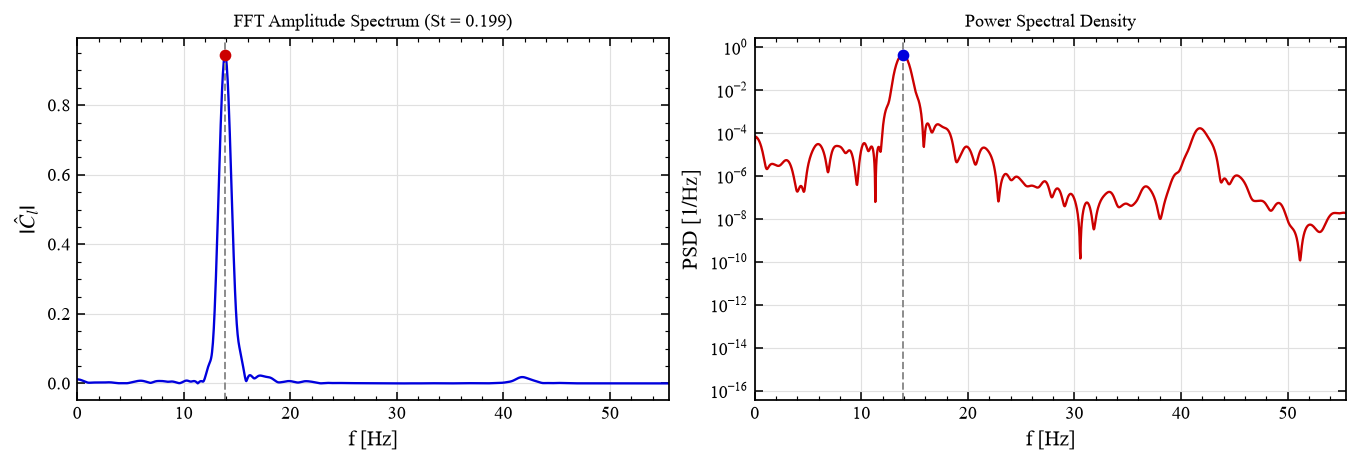

In [5]:
u_inf = None if snaps.ref is None else snaps.ref['u_inf']
plot_spectrum(case, u_inf)

圆柱表面压力系数的展向分布。

wall nodes per plane = 100, planes = 30
Cp min = -1.7950, Cp max = 1.0311
spanwise Cp spread = 0.1236
C:\Users\Administrator\Desktop\PurineCFD-Plugin\results\3D-7-cyc-urans-tfbf\cp_surface.png


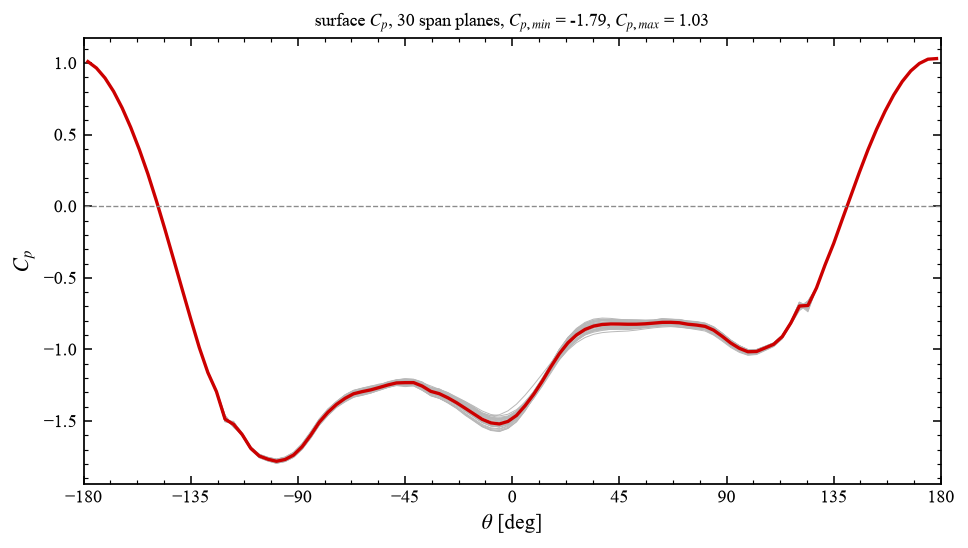

In [6]:
plot_cp_surface(case)

中展向 1/3 段表面 $C_p$ 的时程与时间平均。

Cp time-mean: min = -1.4417 at theta = 99.0 deg
Cp time-mean: max = 1.0192 at theta = -178.2 deg
Cp range at theta = 0 deg over time: -1.5891 ... -0.5785
C:\Users\Administrator\Desktop\PurineCFD-Plugin\results\3D-7-cyc-urans-tfbf\cp_surface_time.png


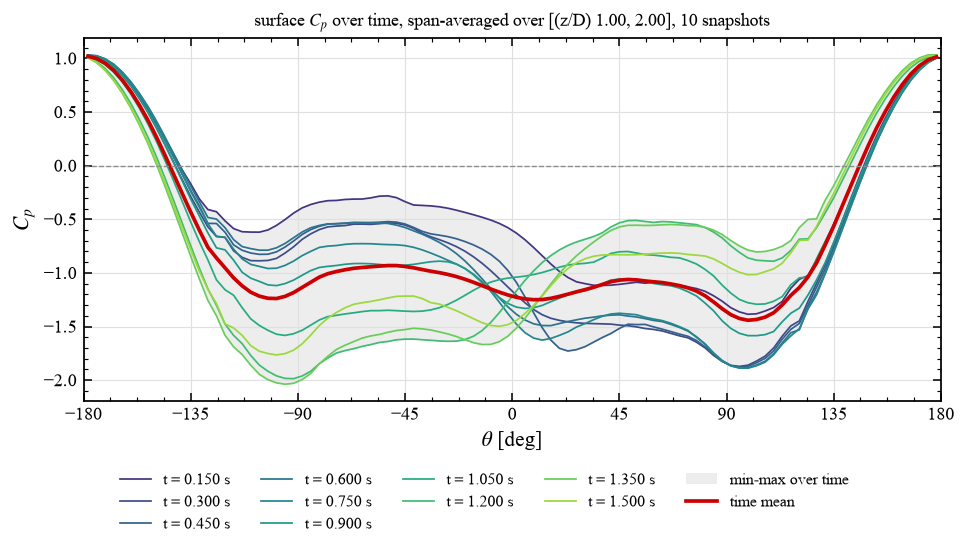

In [7]:
plot_cp_surface_time(case, snaps.cp_curves)

读取 `field.csv`，推算网格维度、远场参考量与中展向截面。

In [8]:
field = load_field(case)

field nodes = 240000
planes = 30, radial = 80, tangential = 100
z/D = 0.050 ... 2.950, mid-span = 1.500
section from z/D = 1.550 and 1.450
D = 0.9995 m, rho_inf = 2.6593e-04 kg/m3, U_inf = 69.623 m/s
p_inf = 22.9002 Pa, q_inf = 0.644522 Pa


中展向截面 $u$、$v$ 云图。

wide view: x/D = -3.0 ... 12.0, y/D = -3.0 ... 3.0
nodes in view = 4698
u = -32.636 ... 108.838 m/s
v = -58.986 ... 75.168 m/s
C:\Users\Administrator\Desktop\PurineCFD-Plugin\results\3D-7-cyc-urans-tfbf\wide_view.png


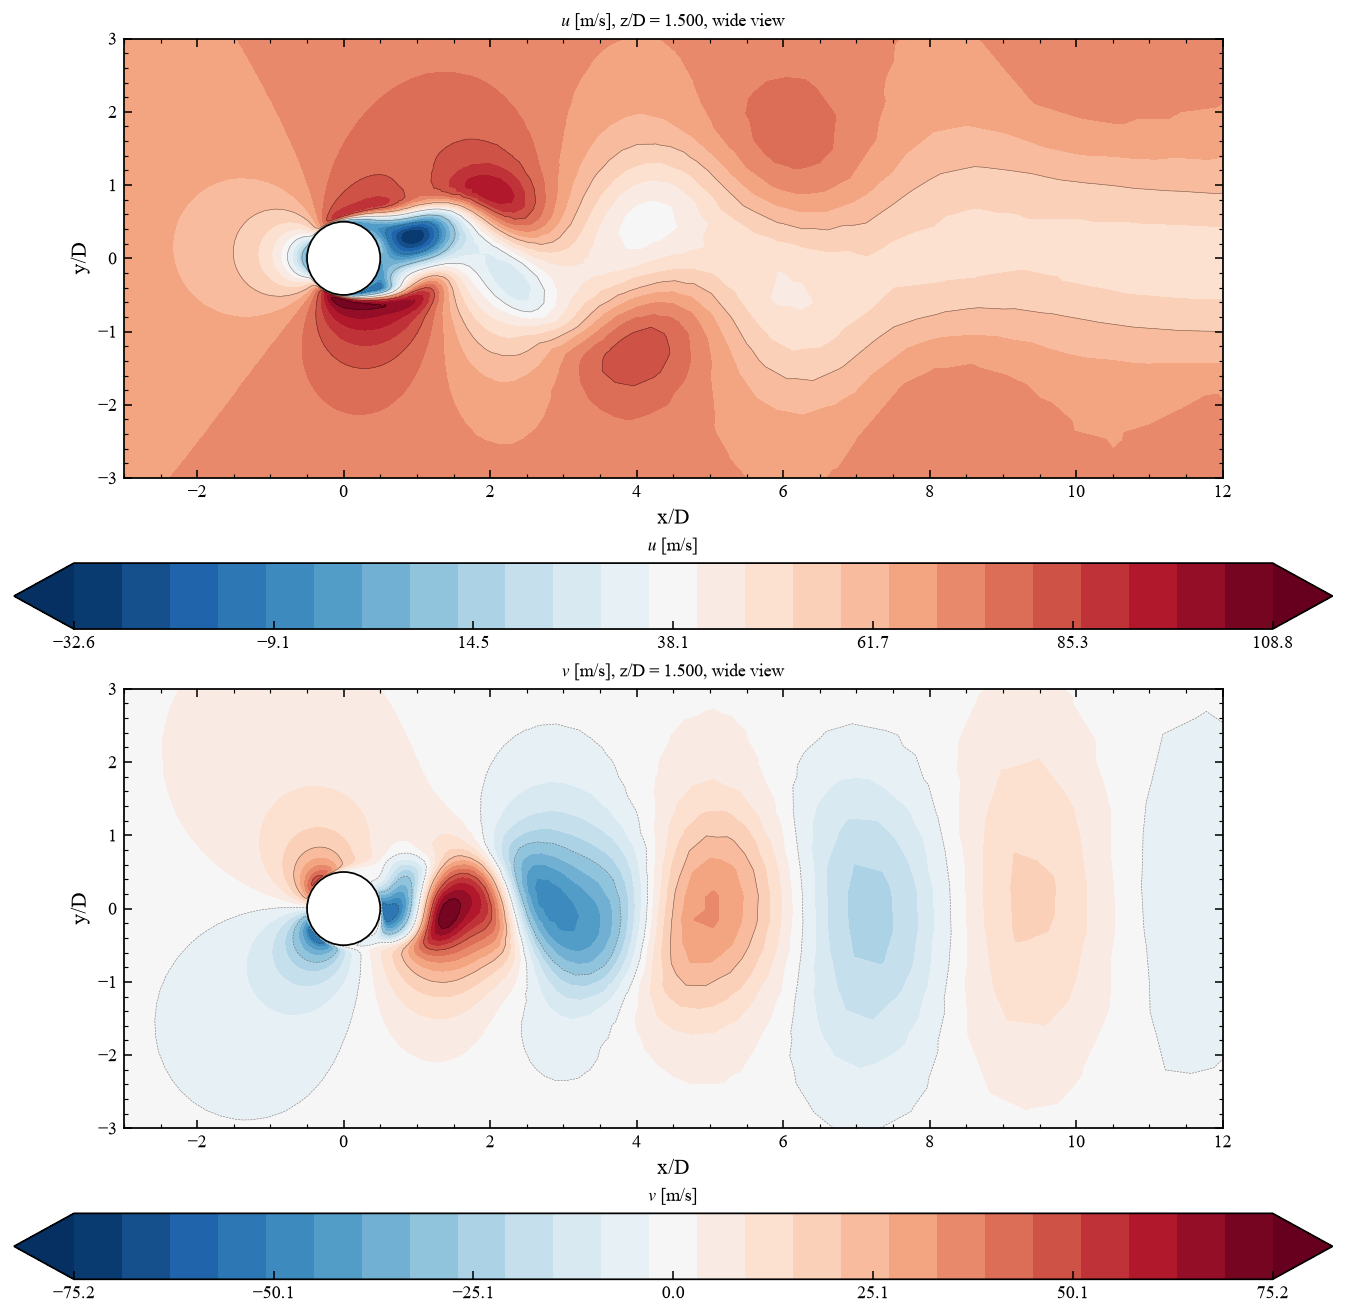

In [9]:
plot_wide_view(case, field)

$y/D = 0$ 俯视 $w$ 云图。

slice points = 4800, x = -29.186 ... 29.186
spanwise w rms = 0.7812 m/s, |w|max = 6.6522 m/s
C:\Users\Administrator\Desktop\PurineCFD-Plugin\results\3D-7-cyc-urans-tfbf\w_top.png


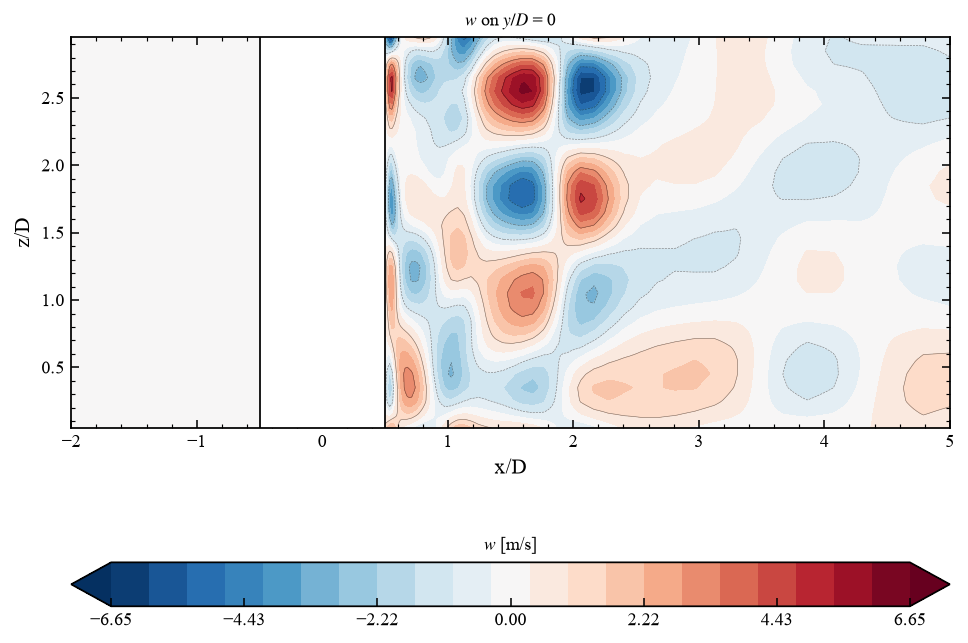

In [10]:
plot_w_top(case, field)

Q 准则三维涡识别：等轴俯视视角，展向 $z$ 沿水平方向铺开。
左图为 $y/D=0$ 剖面涡量，右图为 Q 等值面按 $\omega_z$ 着色。

Q over 1.10R <= r <= 4.0D: -10.17 ... 22.32
Q iso-surface level = 2, triangles = 47768, connected regions = 10
face |omega| D/U_inf = 2.49 ... 21.85, color range 2.70 ... 17.72
note: Q is almost uniform along z (spanwise std 0.06 vs radial 2.49), so vortices appear as spanwise rollers
C:\Users\Administrator\Desktop\PurineCFD-Plugin\results\3D-7-cyc-urans-tfbf\q_criterion.png


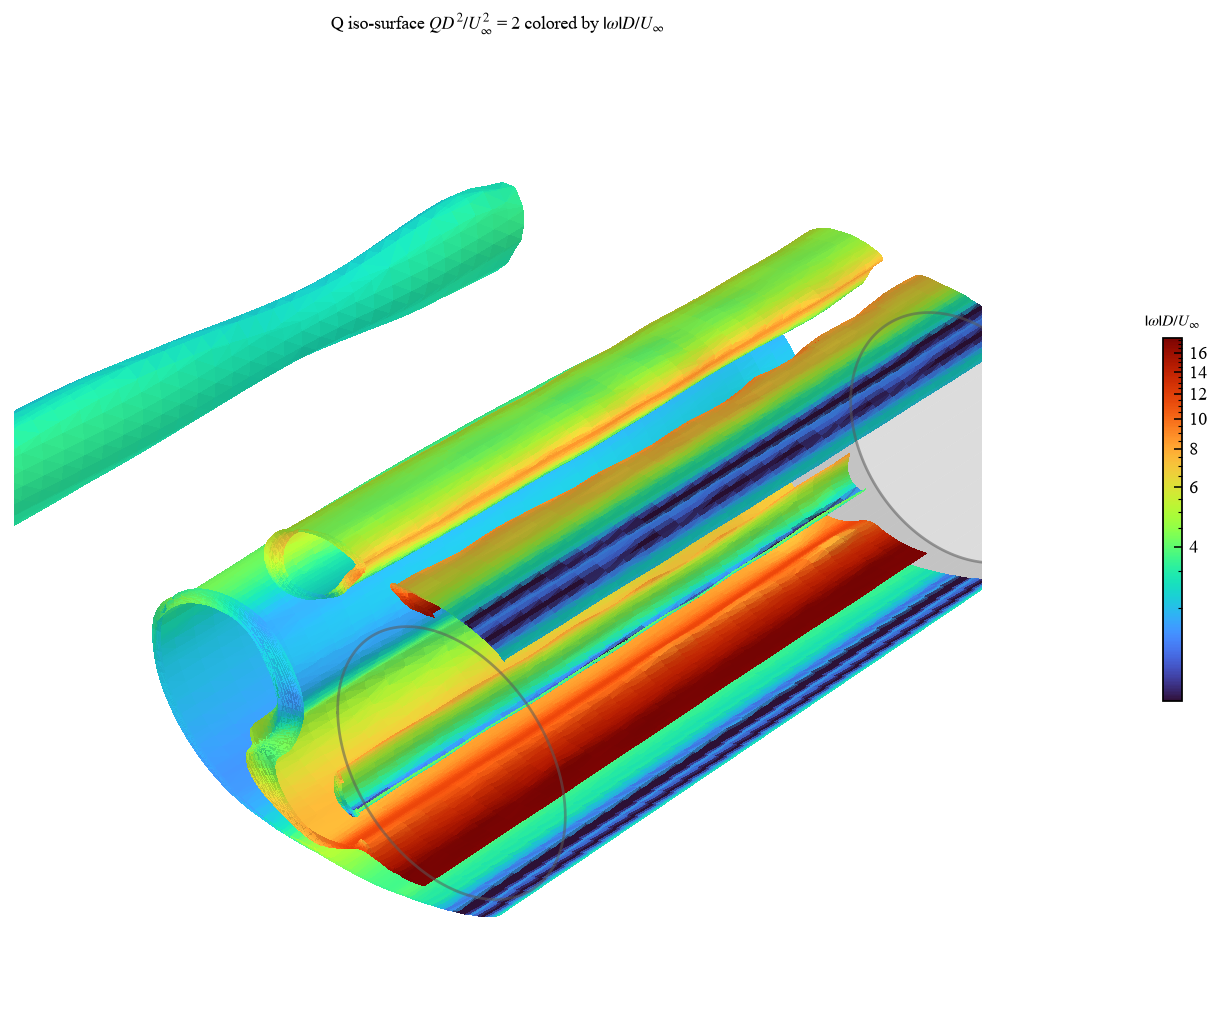

In [11]:
plot_q_criterion(case, field)